## Day: Implied Vol

In [1]:
%load_ext autoreload
%autoreload 1

%aimport openqai.core
%aimport openqai.data.massive.client
%aimport openqai.data.massive.processing
%aimport openqai.data.massive.options.contracts
%aimport openqai.benchmarks.ncde.implied.day

In [2]:



from datetime import date
from cdxcore.jcpool import JCPool
from cdxcore.pretty import PrettyObject
from cdxcore.subdir import SubDir
from cdxcore.util import fmt_list
from cdxcore.uniquehash import named_unique_filename48_8
import polars as pl

from openqai.core.biz_calendar import prev_business_day
from openqai.data.massive.client import MassiveClient
from openqai.core.pool import PoolConfig
from openqai.data.massive.options.contracts import ContractsFilter, filter_contracts, REJECTED
from openqai.data.massive.processing import TradeQuoteAlignmentConfig, align_trades_to_quotes, align_quotes_to_trades, filter_valid_quotes, filter_valid_trades

from cdxcore.version import version
from cdxcore.verbose import Context
from dataclasses import asdict, dataclass, field
from cdxcore.uniquehash import unique_hash8 
import numpy as np
import math
import warnings

from IPython.display import display, Markdown, clear_output

from openqai.benchmarks.ncde.implied.day import OptionQuotesDayConfig, generate_day

option_quotes_day_config = OptionQuotesDayConfig()
ticker     = "SPY"
d          = prev_business_day(date(2025,1,23), exclude_half_days=True, count_start=True )
pool_config= PoolConfig(num_workers=4, threading=False) 
results    = generate_day( ticker, d, option_quotes_day_config=option_quotes_day_config, pool_config=pool_config, verbose=Context.all )

for expiry, df_dict in results.items():
    opt_tickers = sorted( df_dict["opt_ticker"].unique().to_list() )
    df_opt = df_dict.filter(pl.col("opt_ticker") == opt_tickers[0])
    display(df_opt)



00: SPY 2025-01-23: Starting data generation with config mxn=1000,max_dte=7,max_mns=2,min_opt_vol_k=0,bck=250,fwd=250):
00: SPY 2025-01-23: Limiting to at most 1000 options per expiry, selected by smallest absolute nms5:
01:   SPY 2025-01-23 expiry 2025-01-23: Selected 32/32 options, sorted by smallest absolute nms5. Resulting options range from nms5 -0.848 to 0.851.
01:   SPY 2025-01-23 expiry 2025-01-24: Selected 52/52 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.104 to 1.097.
01:   SPY 2025-01-23 expiry 2025-01-27: Selected 50/50 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.233 to 1.219.
01:   SPY 2025-01-23 expiry 2025-01-28: Selected 54/54 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.351 to 1.330.
01:   SPY 2025-01-23 expiry 2025-01-29: Selected 59/59 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.372 to 1.433.
01:   SPY 2025-01-23 expiry 2025-0

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,0.998928,100.0,0.000009,null,0.000003,0.000003,0.01132,0.000404,0.99892,0.000025,2.0,0.5,600.0,0.166667,null,0.333333,null,null,null,null,0.799993,null,null,null,null,446.73011,2025-01-23,2025-01-23,0.987732,"""SPY""","""O:SPY250123C00599000""",true,true,606.44,0.000016,0.011188,true,1.0,0.0,0.0,0.0,0.0001,0.885815,20.572799,0.010881,0.285532,0.166608,0.955898,14.089284,0.005255,0.097227,0.11748
0.011229,2.0,0.998892,1.0,0.000034,0.000043,0.000034,0.000034,0.011287,0.000404,0.998879,0.000016,2.0,0.5,700.0,0.142857,-0.142857,0.78,-0.002913,null,-0.000037,-0.000041,0.799973,0.000026,null,0.000031,0.000031,446.733783,2025-01-23,2025-01-23,0.987732,"""SPY""","""O:SPY250123C00599000""",true,true,606.44,0.000016,0.011147,true,1.0,0.0,0.0,0.0,0.0001,0.884574,20.696714,0.010965,0.288229,0.166891,0.953804,14.488572,0.005454,0.101879,0.118589
0.011229,2.0,0.998846,10.0,0.000043,0.000043,0.000043,0.000043,0.011238,0.000107,0.998846,0.000016,20.0,0.5,800.0,0.625,-0.076923,0.0,-0.004383,0.0,-0.000046,-0.000033,0.799965,0.000009,0.0,0.000009,0.000009,446.73637,2025-01-23,2025-01-23,0.987732,"""SPY""","""O:SPY250123C00599000""",true,true,606.44,0.000016,0.011114,true,0.996759,2.384329,0.000553,0.006354,0.073004,0.933419,17.294321,0.007278,0.151975,0.132571,0.958032,13.81321,0.005048,0.091537,0.115124
0.011229,2.0,0.998796,1.0,0.000044,0.000043,0.000044,0.000044,0.011287,0.000404,0.998821,0.000025,2.0,0.5,600.0,0.5,-0.142857,-1.0,0.004402,0.0,-0.00005,-0.000025,0.799965,6.8944e-7,0.0,9.0667e-7,9.2098e-7,446.73812,2025-01-23,2025-01-23,0.987732,"""SPY""","""O:SPY250123C00599000""",true,true,606.44,0.000016,0.011089,true,1.0,0.0,0.0,0.0,0.0001,0.877202,21.056283,0.011455,0.309192,0.171371,0.940354,16.505868,0.006681,0.13416,0.127499
0.011229,2.0,0.998763,100.0,0.000044,0.000043,0.000044,0.000044,0.011287,0.000404,0.998763,0.000033,8.0,0.5,500.0,0.4,-0.142857,3.3664e-12,0.0,0.0,-0.000033,-0.000058,0.799965,2.3705e-7,0.0,4.2846e-7,4.4786e-7,446.742163,2025-01-23,2025-01-23,0.987732,"""SPY""","""O:SPY250123C00599000""",true,true,606.44,0.000016,0.011032,true,1.0,0.0,0.0,0.0,0.0001,0.870197,21.355,0.011906,0.329377,0.175635,0.928528,17.948039,0.007687,0.16335,0.134917
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005359,100.0,0.999967,null,0.999966,0.999966,0.016951,0.001632,1.005367,0.000008,95.0,0.010526,900.0,0.888889,null,-1.0,-0.034288,null,0.000016,0.000016,0.000026,0.000001,null,0.000002,0.000002,480.657545,2025-01-23,2025-01-23,0.987732,"""SPY""","""O:SPY250123C00599000""",true,true,606.44,0.000016,0.017636,true,1.0,0.0,0.0,0.0,0.0001,1.0,3.1195e-24,1.6387e-30,3.8994e-23,5.0,1.0,0.0,0.0,0.0,0.0001
null,null,1.005343,200.0,0.99997,null,0.999969,0.999968,0.016943,0.001641,1.005351,0.000008,114.0,0.175439,1600.0,0.9375,null,-1.0,-0.000486,null,-0.000016,-0.000016,0.000024,0.000003,null,0.000002,0.000002,480.658897,2025-01-23,2025-01-23,0.987732,"""SPY""","""O:SPY250123C00599000""",true,true,606.44,0.000016,0.017619,true,1.0,0.0,0.0,0.0,0.0001,1.0,8.6585e-27,4.1289e-33,1.0823e-25,5.0,1.0,0.0,0.0,0.0,0.0001
null,null,1.005407,1.0,0.999982,null,0.999982,0.999982,0

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,0.998928,100.0,0.000005,null,0.000003,0.000003,0.016646,0.000404,0.99892,0.000025,2.0,0.5,600.0,0.166667,null,0.333333,null,null,null,null,1.799996,null,null,null,null,412.25279,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124C00596000""",true,true,606.44,0.000016,0.016135,false,0.972505,7.440684,0.005348,0.037675,0.100632,0.874342,14.463965,0.017462,0.20659,0.169015,0.911932,13.214313,0.013505,0.135254,0.143076
null,null,0.998928,100.0,0.00001,null,0.000003,0.000003,0.016663,0.000124,0.99892,0.000025,20.0,0.5,600.0,0.166667,null,0.333333,0.000991,null,0.0,0.0,1.799992,0.000005,null,0.0,0.0,412.252915,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124C00596000""",true,true,606.44,0.000016,0.016135,false,0.924578,12.491379,0.012015,0.113256,0.13466,0.897439,13.838551,0.015108,0.161645,0.152845,0.910111,13.303976,0.013712,0.138498,0.144293
null,null,0.998912,1.0,0.000024,null,0.000024,0.000024,0.016646,0.000404,0.998903,0.000008,2.0,0.5,1200.0,0.083333,null,1.0,-0.00099,null,-0.000017,-0.000017,1.799981,0.000014,null,0.000021,0.000021,412.254314,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124C00596000""",true,true,606.44,0.000016,0.016119,false,0.96894,8.011248,0.005918,0.04285,0.103428,0.872988,14.503214,0.017593,0.209135,0.169823,0.910081,13.318988,0.013715,0.138412,0.144167
null,null,0.998892,1.0,0.000035,null,0.000034,0.000034,0.016613,0.000404,0.998879,0.000016,2.0,0.5,400.0,0.25,null,0.81,-0.001981,null,-0.00002,-0.000025,1.799972,0.00001,null,0.00001,0.00001,412.256165,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124C00596000""",true,true,606.44,0.000016,0.016094,false,0.970763,7.740694,0.005629,0.040115,0.101807,0.873556,14.515338,0.017538,0.207661,0.169153,0.910944,13.297222,0.013617,0.136664,0.143371
null,null,0.998945,3.0,0.000037,null,0.000036,0.000029,0.01658,0.000124,0.99892,0.000025,20.0,0.5,1200.0,0.083333,null,1.0,-0.001985,null,0.000053,0.000041,1.799971,0.000002,null,0.000002,-0.000005,412.253552,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124C00596000""",true,true,606.44,0.000016,0.016135,false,0.935425,11.71355,0.010662,0.095103,0.127429,0.905685,13.508005,0.014209,0.14647,0.147263,0.919535,12.801595,0.01262,0.12192,0.138013
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005409,50.0,0.999988,null,0.999988,0.999987,0.022855,0.000198,1.005425,0.000016,35.0,0.714286,1300.0,0.923077,null,-1.0,-0.00216,null,-0.000033,-0.000008,1.00001,0.000003,null,0.000002,0.000002,438.430384,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124C00596000""",true,true,606.44,0.000016,0.02264,true,0.970477,5.547627,0.00423,0.102392,0.19213,0.9253,8.88362,0.00889,0.282468,0.252177,0.944936,7.77537,0.007014,0.200901,0.227324
null,null,1.005425,1.0,0.999992,null,0.999991,0.999991,0.022838,0.000181,1.0054,0.000025,29.0,0.862069,300.0,0.666667,null,1.0,-0.000722,null,0.000016,-0.000025,1.000006,0.000004,null,0.000004,0.000004,438.432202,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124C00596000""",true,true,606.44,0.000016,0.022616,false,0.966829,5.946625,0.004657,0.115821,0.197367,0.926054,8.85787,0.008821,0.27

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,0.998928,100.0,0.000009,null,0.000003,0.000003,0.020159,0.000635,0.99892,0.000025,2.0,0.5,600.0,0.166667,null,0.333333,null,null,null,null,2.799993,null,null,null,null,384.717861,2025-01-27,2025-01-23,0.979487,"""SPY""","""O:SPY250127C00594000""",true,true,606.44,0.000016,0.019433,false,0.980176,5.021047,0.005066,0.020698,0.0908,0.858808,12.144211,0.023597,0.185696,0.174877,0.902434,11.299518,0.018169,0.118314,0.144712
null,null,0.998846,10.0,0.000043,null,0.000043,0.000043,0.020134,0.000115,0.998846,0.000016,20.0,0.5,800.0,0.625,null,0.0,-0.001227,null,-0.000083,-0.000074,2.799965,0.000035,null,0.00004,0.00004,384.72302,2025-01-27,2025-01-23,0.979487,"""SPY""","""O:SPY250127C00594000""",true,true,606.44,0.000016,0.019359,false,0.908056,11.139839,0.017391,0.109958,0.140504,0.889318,11.723687,0.019909,0.136925,0.152836,0.898315,11.475695,0.018726,0.123756,0.146862
null,null,0.998846,97.0,0.000049,null,0.000049,0.000049,0.020117,0.000132,0.998829,0.000016,20.0,0.5,400.0,0.25,null,1.0,-0.000819,null,0.0,-0.000017,2.799961,0.000006,null,0.000006,0.000006,384.724123,2025-01-27,2025-01-23,0.979487,"""SPY""","""O:SPY250127C00594000""",true,true,606.44,0.000016,0.019342,false,0.909516,11.092373,0.017186,0.107838,0.139441,0.888056,11.764044,0.020071,0.138689,0.153553,0.898287,11.486298,0.01873,0.123692,0.146756
null,null,0.998813,80.0,0.00005,null,0.000049,0.000049,0.020101,0.000115,0.998829,0.000016,20.0,0.5,400.0,0.25,null,-1.0,-0.00082,null,-0.000033,0.0,2.79996,7.6701e-7,null,3.1487e-7,0.0,384.724138,2025-01-27,2025-01-23,0.979487,"""SPY""","""O:SPY250127C00594000""",true,true,606.44,0.000016,0.019342,false,0.909516,11.092373,0.017186,0.107838,0.139441,0.890528,11.703532,0.019752,0.135016,0.151897,0.899635,11.444174,0.018548,0.121757,0.145871
null,null,0.998813,10.0,0.000052,null,0.000051,0.000051,0.020093,0.000124,0.998796,0.000016,60.0,0.166667,900.0,0.888889,null,1.0,-0.00041,null,0.0,-0.000033,2.799958,0.000002,null,0.000002,0.000003,384.726173,2025-01-27,2025-01-23,0.979487,"""SPY""","""O:SPY250127C00594000""",true,true,606.44,0.000016,0.019309,false,0.907991,11.170772,0.0174,0.10977,0.140189,0.887988,11.785682,0.02008,0.138555,0.153338,0.897563,11.527974,0.018826,0.124524,0.146982
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005409,50.0,0.999988,null,0.999988,0.999987,0.026318,0.000198,1.005425,0.000016,40.0,0.625,1300.0,0.923077,null,-1.0,0.0,null,0.0,-0.000008,2.00001,4.2449e-7,null,5.6521e-7,5.2090e-7,405.694015,2025-01-27,2025-01-23,0.979487,"""SPY""","""O:SPY250127C00594000""",true,true,606.44,0.000016,0.025938,false,0.951465,6.363162,0.008973,0.10043,0.177668,0.917574,8.025237,0.013546,0.181504,0.212681,0.933021,7.397674,0.011561,0.143425,0.196916
null,null,1.005409,50.0,0.999988,null,0.999988,0.999987,0.026268,0.000148,1.005425,0.000016,35.0,0.714286,1300.0,0.923077,null,-1.0,-0.00188,null,0.0,0.0,2.00001,3.5449e-7,null,0.0,0.0,405.694023,2025-01-27,2025-01-23,0.979487,"""SPY""","""O:SPY250127C00594000""",true,true,606.44,0.000016,0.025938,false,0.951465,6.363162,0.008973,0.10043,0.177668,0.925004,7.746747,0.01261,0.162944,0.205104,0.9

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,0.998928,3.0,6.6137e-7,null,2.9299e-7,2.7466e-7,0.023605,0.000635,0.998928,0.000016,2.0,0.5,1000.0,0.3,null,0.0,null,null,null,null,3.799999,null,null,null,null,362.008041,2025-01-28,2025-01-23,0.976189,"""SPY""","""O:SPY250128C00592000""",true,true,606.44,0.000016,0.022739,false,0.96097,6.439766,0.010373,0.036739,0.106817,0.863672,10.312247,0.026841,0.153621,0.172609,0.901538,9.655965,0.021308,0.103393,0.14634
null,null,0.998912,1.0,0.000024,null,0.000024,0.000024,0.023539,0.000569,0.998903,0.000008,16.0,0.0625,1200.0,0.083333,null,1.0,-0.002794,null,-0.000017,-0.000025,3.799981,0.000023,null,0.000024,0.000024,362.009832,2025-01-28,2025-01-23,0.976189,"""SPY""","""O:SPY250128C00592000""",true,true,606.44,0.000016,0.022715,false,0.957806,6.72529,0.01105,0.039924,0.108963,0.869233,10.27257,0.026083,0.14563,0.168384,0.9044,9.583326,0.020852,0.099763,0.144292
null,null,0.998895,1.0,0.000036,null,0.000035,0.000035,0.023605,0.000124,0.998879,0.000016,20.0,0.5,300.0,0.333333,null,1.0,0.002802,null,-0.000017,-0.000025,3.799971,0.000012,null,0.000011,0.000011,362.011428,2025-01-28,2025-01-23,0.976189,"""SPY""","""O:SPY250128C00592000""",true,true,606.44,0.000016,0.02269,false,0.90682,9.51908,0.020461,0.09671,0.142545,0.889838,9.96353,0.023115,0.117916,0.153849,0.89803,9.771672,0.021859,0.107527,0.148351
null,null,0.998846,30.0,0.000037,null,0.000037,0.000036,0.023613,0.000132,0.998846,0.000033,20.0,0.5,1300.0,0.461538,null,0.0,0.000349,null,-0.00005,-0.000033,3.79997,0.000002,null,0.000001,0.000002,362.013327,2025-01-28,2025-01-23,0.976189,"""SPY""","""O:SPY250128C00592000""",true,true,606.44,0.000016,0.022657,false,0.904342,9.609367,0.020861,0.099581,0.143965,0.886669,10.041837,0.023588,0.121841,0.155778,0.895189,9.857039,0.0223,0.110936,0.15003
null,null,0.998846,30.0,0.000038,null,0.000037,0.000036,0.023597,0.000115,0.998846,0.000033,20.0,0.5,1300.0,0.461538,null,0.0,-0.000698,null,0.0,0.0,3.79997,3.7333e-7,null,0.0,0.0,362.013333,2025-01-28,2025-01-23,0.976189,"""SPY""","""O:SPY250128C00592000""",true,true,606.44,0.000016,0.022657,false,0.904342,9.609367,0.020861,0.099582,0.143965,0.888739,10.000757,0.02328,0.11916,0.15437,0.896301,9.829765,0.022128,0.109537,0.149287
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005334,100.0,0.999976,null,0.999974,0.999974,0.029714,0.000165,1.005334,0.000008,53.0,0.622642,1200.0,0.916667,null,0.0,0.0,null,0.0,0.0,3.000019,9.4004e-7,null,0.0,0.0,379.29662,2025-01-28,2025-01-23,0.976189,"""SPY""","""O:SPY250128C00592000""",true,true,606.44,0.000016,0.029146,false,0.935043,6.481601,0.013827,0.104068,0.179198,0.912565,7.270296,0.017341,0.145918,0.200352,0.923188,6.940531,0.015728,0.125747,0.190356
null,null,1.005392,1.0,0.999983,null,0.999983,0.999983,0.029731,0.000148,1.005392,0.000016,20.0,0.5,1000.0,0.7,null,0.0,0.000555,null,0.000057,0.000057,3.000013,0.000007,null,0.000008,0.000009,379.29334,2025-01-28,2025-01-23,0.976189,"""SPY""","""O:SPY250128C00592000""",true,true,606.44,0.000016,0.029203,false,0.936845,6.389769,0.013528,0.101044,0.177839,0.916143,7.152996,0.016807,0.139317,0.197366,0.925979,6.828294,0.015291,

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,0.998846,10.0,0.0000433,null,0.000043,0.000043,0.025633,0.000124,0.998846,0.000016,20.0,0.5,800.0,0.625,null,0.0,null,null,null,null,4.799965,null,null,null,null,342.955578,2025-01-29,2025-01-23,0.97454,"""SPY""","""O:SPY250129C00591000""",true,true,606.44,0.000016,0.024306,false,0.884726,9.380943,0.026834,0.105783,0.150176,0.871465,9.562634,0.028967,0.120931,0.159036,0.877904,9.484762,0.027947,0.113481,0.15469
null,null,0.998846,10.0,0.000044,null,0.000043,0.000043,0.025617,0.000107,0.998846,0.000016,20.0,0.5,800.0,0.625,null,0.0,-0.000643,null,0.0,0.0,4.799965,2.1115e-7,null,0.0,0.0,342.955581,2025-01-29,2025-01-23,0.97454,"""SPY""","""O:SPY250129C00591000""",true,true,606.44,0.000016,0.024306,false,0.884726,9.380943,0.026834,0.105783,0.150176,0.873147,9.544105,0.028703,0.118967,0.157892,0.87879,9.472542,0.027804,0.11247,0.154099
null,null,0.998796,1.0,0.000044,null,0.000044,0.000044,0.025411,0.000346,0.998821,0.000025,31.0,0.483871,600.0,0.5,null,-1.0,-0.008046,null,-0.00005,-0.000025,4.799965,4.8795e-7,null,9.0667e-7,9.2098e-7,342.956919,2025-01-29,2025-01-23,0.97454,"""SPY""","""O:SPY250129C00591000""",true,true,606.44,0.000016,0.024281,false,0.911579,8.735274,0.022119,0.077186,0.132937,0.870174,9.585741,0.029169,0.122323,0.159756,0.888992,9.313645,0.026121,0.100965,0.147245
null,null,0.998813,500.0,0.000048,null,0.000048,0.000048,0.025584,0.000124,0.998821,0.000008,20.0,0.5,800.0,0.75,null,-1.0,0.006814,null,0.000017,-1.1115e-16,4.799962,0.000004,null,0.000004,0.000004,342.956974,2025-01-29,2025-01-23,0.97454,"""SPY""","""O:SPY250129C00591000""",true,true,606.44,0.000016,0.024281,false,0.886106,9.366639,0.026605,0.104144,0.149122,0.87268,9.559077,0.028777,0.11939,0.158048,0.879196,9.476432,0.027738,0.111894,0.153672
null,null,0.998813,3.0,0.000053,null,0.000053,0.000053,0.025567,0.000107,0.998804,0.000025,20.0,0.5,800.0,0.125,null,0.333333,-0.000645,null,0.0,-0.000017,4.799958,0.000005,null,0.000005,0.000005,342.957928,2025-01-29,2025-01-23,0.97454,"""SPY""","""O:SPY250129C00591000""",true,true,606.44,0.000016,0.024265,false,0.885137,9.389834,0.026766,0.105149,0.149654,0.873499,9.556234,0.028648,0.118357,0.157387,0.87917,9.483229,0.027742,0.111848,0.153586
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005392,1.0,0.999983,null,0.999983,0.999983,0.031611,0.000148,1.005392,0.000016,43.0,0.767442,1000.0,0.7,null,0.0,0.0,null,0.0,0.0,4.000013,3.7436e-8,null,0.0,0.0,357.506437,2025-01-29,2025-01-23,0.97454,"""SPY""","""O:SPY250129C00591000""",true,true,606.44,0.000016,0.030852,false,0.922657,6.56556,0.018257,0.100746,0.175184,0.905356,7.034147,0.021236,0.127222,0.190191,0.913622,6.831216,0.019842,0.114376,0.182993
null,null,1.005409,1.0,0.999986,null,0.999986,0.999985,0.03171,0.000247,1.005417,0.000008,24.0,0.958333,2900.0,0.896552,null,-1.0,0.00313,null,0.000016,0.000025,4.000011,0.000002,null,0.000003,0.000002,357.505092,2025-01-29,2025-01-23,0.97454,"""SPY""","""O:SPY250129C00591000""",true,true,606.44,0.000016,0.030877,false,0.924223,6.509251,0.017975,0.098504,0.173971,0.896428,7.209049,0.022683,0.141635,0.198226,0.90937,6.934589,0.020566,0

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,0.998928,100.0,0.000008,null,0.000003,0.000003,0.027678,0.000635,0.99892,0.000025,2.0,0.5,600.0,0.166667,null,0.333333,null,null,null,null,5.799993,null,null,null,null,326.601445,2025-01-30,2025-01-23,0.972891,"""SPY""","""O:SPY250130C00590000""",true,true,606.44,0.000016,0.026029,false,0.90036,8.440965,0.026555,0.078852,0.136686,0.841387,9.042072,0.036703,0.140621,0.176362,0.867137,8.954944,0.03258,0.11188,0.158073
null,null,0.998928,100.0,0.00001,null,0.000003,0.000003,0.027711,0.000107,0.99892,0.000025,20.0,0.5,600.0,0.166667,null,0.333333,0.001192,null,0.0,0.0,5.799992,0.000002,null,0.0,0.0,326.60147,2025-01-30,2025-01-23,0.972891,"""SPY""","""O:SPY250130C00590000""",true,true,606.44,0.000016,0.026029,false,0.870556,8.924848,0.031998,0.108286,0.155776,0.860926,8.997861,0.033615,0.118535,0.162318,0.865649,8.966586,0.03283,0.113459,0.159082
null,null,0.998912,1.0,0.000024,null,0.000024,0.000024,0.027678,0.000635,0.998903,0.000008,2.0,0.5,1200.0,0.083333,null,1.0,-0.00119,null,-0.000017,-0.000017,5.799981,0.000014,null,0.000021,0.000021,326.602483,2025-01-30,2025-01-23,0.972891,"""SPY""","""O:SPY250130C00590000""",true,true,606.44,0.000016,0.026012,false,0.899346,8.470048,0.026752,0.079751,0.137227,0.840751,9.047097,0.036799,0.141282,0.176728,0.866362,8.966784,0.03271,0.11263,0.158498
null,null,0.998945,3.0,0.000037,null,0.000036,0.000029,0.027645,0.000124,0.99892,0.000025,20.0,0.5,1200.0,0.083333,null,1.0,-0.001192,null,0.000033,0.000017,5.799971,0.000013,null,0.000012,0.000005,326.601789,2025-01-30,2025-01-23,0.972891,"""SPY""","""O:SPY250130C00590000""",true,true,606.44,0.000016,0.026029,false,0.874478,8.884422,0.031321,0.104221,0.153172,0.863065,8.984753,0.033261,0.116224,0.160846,0.868644,8.942257,0.032324,0.11029,0.157058
null,null,0.998829,1.0,0.000039,null,0.000039,0.000037,0.027661,0.000107,0.998854,0.000025,20.0,0.5,800.0,0.625,null,-1.0,0.000596,null,-0.000116,-0.000066,5.799969,0.000002,null,0.000002,0.000008,326.605195,2025-01-30,2025-01-23,0.972891,"""SPY""","""O:SPY250130C00590000""",true,true,606.44,0.000016,0.025963,false,0.869678,8.955665,0.032148,0.108928,0.155968,0.860096,9.025317,0.033751,0.119134,0.162481,0.864755,8.995915,0.03298,0.114123,0.159287
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005409,50.0,0.999988,null,0.999988,0.999987,0.033589,0.000148,1.005425,0.000016,66.0,0.5,1300.0,0.923077,null,-1.0,0.0,null,0.0,0.0,5.000009,8.7154e-7,null,0.0,0.0,339.068658,2025-01-30,2025-01-23,0.972891,"""SPY""","""O:SPY250130C00590000""",true,true,606.44,0.000016,0.032534,false,0.907958,6.604808,0.023258,0.104019,0.177477,0.893496,6.880774,0.025878,0.123609,0.189549,0.900487,6.759142,0.024632,0.114013,0.183673
null,null,1.005392,7.0,0.999991,null,0.999991,0.99999,0.033589,0.000148,1.005409,0.000016,56.0,0.410714,1100.0,0.909091,null,-0.99,0.0,null,-0.000016,-0.000016,5.000007,0.000003,null,0.000003,0.000003,339.069565,2025-01-30,2025-01-23,0.972891,"""SPY""","""O:SPY250130C00590000""",true,true,606.44,0.000016,0.032518,false,0.907105,6.627109,0.023417,0.105094,0.178091,0.892742,6.896131,0.02601,0.124596,0.190092,0.899687,6.7775

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,0.998928,100.0,0.000011,null,0.000003,0.000003,0.031471,0.000107,0.99892,0.000025,20.0,0.5,600.0,0.166667,null,0.333333,null,null,null,null,6.799991,null,null,null,null,312.289832,2025-01-31,2025-01-23,0.969593,"""SPY""","""O:SPY250131C00588000""",true,true,606.44,0.000016,0.029327,false,0.860495,7.962706,0.036474,0.114728,0.169754,0.852666,7.99051,0.037844,0.123077,0.175516,0.856516,7.979288,0.037176,0.118938,0.17266
null,null,0.998945,3.0,0.000037,null,0.000036,0.000029,0.031405,0.000124,0.99892,0.000025,20.0,0.5,1200.0,0.083333,null,1.0,-0.002096,null,0.000017,0.0,6.799971,0.000026,null,0.000034,0.000027,312.290105,2025-01-31,2025-01-23,0.969593,"""SPY""","""O:SPY250131C00588000""",true,true,606.44,0.000016,0.029327,false,0.863645,7.94587,0.035911,0.111445,0.167484,0.854427,7.985955,0.03754,0.121175,0.174204,0.858949,7.969762,0.036748,0.116356,0.170878
null,null,0.998846,30.0,0.000038,null,0.000037,0.000036,0.031405,0.000124,0.998846,0.000033,43.0,0.232558,1300.0,0.461538,null,0.0,0.0,null,-0.000099,-0.000074,6.79997,8.2996e-7,null,3.3209e-7,0.000007,312.293751,2025-01-31,2025-01-23,0.969593,"""SPY""","""O:SPY250131C00588000""",true,true,606.44,0.000016,0.029253,false,0.860692,7.98191,0.036439,0.114232,0.169183,0.851667,8.012927,0.038016,0.123849,0.175819,0.856094,8.000967,0.03725,0.119087,0.172534
null,null,0.998829,1.0,0.000039,null,0.000039,0.000037,0.031421,0.000107,0.998854,0.000025,43.0,0.232558,800.0,0.625,null,-1.0,0.000525,null,-0.000017,0.000008,6.799969,0.000001,null,0.000002,5.8491e-7,312.293361,2025-01-31,2025-01-23,0.969593,"""SPY""","""O:SPY250131C00588000""",true,true,606.44,0.000016,0.029261,false,0.859771,7.984034,0.036603,0.11523,0.169897,0.851972,8.010045,0.037964,0.123553,0.175641,0.855807,7.999677,0.0373,0.119426,0.172794
null,null,0.998788,10.0,0.000045,null,0.000045,0.000045,0.031281,0.000247,0.998788,0.000008,24.0,0.041667,200.0,0.5,null,0.0,-0.004461,null,-0.000041,-0.000066,6.799964,0.000006,null,0.000006,0.000008,312.29666,2025-01-31,2025-01-23,0.969593,"""SPY""","""O:SPY250131C00588000""",true,true,606.44,0.000016,0.029195,false,0.868062,7.952224,0.035107,0.10643,0.163607,0.849555,8.032337,0.038376,0.125904,0.177058,0.858432,8.007913,0.03684,0.116377,0.170486
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005442,100.0,0.999985,null,0.999985,0.999985,0.037514,0.00033,1.005433,0.000008,24.0,0.958333,200.0,0.5,null,1.0,0.004193,null,0.000049,0.000041,6.000012,7.7517e-7,null,0.000003,0.000003,323.116636,2025-01-31,2025-01-23,0.969593,"""SPY""","""O:SPY250131C00588000""",true,true,606.44,0.000016,0.03584,false,0.893002,6.235502,0.028443,0.11443,0.191579,0.868759,6.477245,0.032857,0.147008,0.213054,0.880229,6.38703,0.030825,0.131215,0.202702
null,null,1.005409,400.0,0.999987,null,0.999987,0.999987,0.037382,0.000115,1.005433,0.000025,20.0,0.5,1700.0,0.705882,null,-1.0,-0.003516,null,-0.000033,0.0,6.00001,0.000002,null,0.000002,0.000002,323.116658,2025-01-31,2025-01-23,0.969593,"""SPY""","""O:SPY250131C00588000""",true,true,606.44,0.000016,0.03584,false,0.889669,6.280606,0.029077,0.118733,0.194446,0.880835,6.381114,0.0307

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,0.998945,100.0,0.000001,null,8.2812e-7,7.8145e-7,0.028939,0.001979,0.998928,0.000016,2.0,0.5,600.0,0.166667,null,1.0,null,null,null,null,7.799999,null,null,null,null,300.002114,2025-02-03,2025-01-23,0.972891,"""SPY""","""O:SPY250203C00590000""",true,true,606.44,0.000016,0.026037,false,0.906033,8.29463,0.029497,0.054746,0.114892,0.772668,8.333068,0.053073,0.176409,0.205766,0.820851,8.954865,0.046027,0.123469,0.16606
null,null,0.998945,3.0,0.000037,null,0.000036,0.000029,0.028807,0.000115,0.99892,0.000025,20.0,0.5,1200.0,0.083333,null,1.0,-0.004558,null,0.0,-0.000008,7.799971,0.000036,null,0.000036,0.000029,300.002835,2025-02-03,2025-01-23,0.972891,"""SPY""","""O:SPY250203C00590000""",true,true,606.44,0.000016,0.026029,false,0.82835,9.002759,0.044796,0.116331,0.160759,0.821081,8.959319,0.04599,0.123209,0.165843,0.824658,8.98254,0.045407,0.119794,0.163318
null,null,0.998846,30.0,0.000038,null,0.000037,0.000036,0.028824,0.000099,0.998846,0.000033,20.0,0.5,1300.0,0.461538,null,0.0,0.000572,null,-0.000099,-0.000074,7.79997,9.0235e-7,null,3.3209e-7,0.000007,300.006336,2025-02-03,2025-01-23,0.972891,"""SPY""","""O:SPY250203C00590000""",true,true,606.44,0.000016,0.025955,false,0.824725,9.008691,0.045396,0.119388,0.162804,0.818638,8.967113,0.046383,0.125215,0.167116,0.821642,8.988894,0.045899,0.122319,0.164971
null,null,0.998796,1.0,0.000044,null,0.000044,0.000044,0.028816,0.000091,0.998821,0.000025,20.0,0.5,600.0,0.5,null,-1.0,-0.000286,null,-0.00005,-0.000025,7.799965,0.000006,null,0.000007,0.000007,300.007559,2025-02-03,2025-01-23,0.972891,"""SPY""","""O:SPY250203C00590000""",true,true,606.44,0.000016,0.02593,false,0.823882,9.012149,0.045534,0.120071,0.163237,0.818325,8.973278,0.046434,0.1254,0.167182,0.82107,8.993531,0.045992,0.12275,0.165219
null,null,0.998788,10.0,0.000045,null,0.000045,0.000045,0.028865,0.000453,0.998788,0.000008,2.0,0.5,200.0,0.5,null,0.0,0.001717,null,-0.000008,-0.000033,7.799964,0.000001,null,0.000001,0.000001,300.009124,2025-02-03,2025-01-23,0.972891,"""SPY""","""O:SPY250203C00590000""",true,true,606.44,0.000016,0.025897,false,0.832955,9.068503,0.044021,0.111526,0.156832,0.805639,8.865431,0.048409,0.137958,0.176416,0.818482,8.985962,0.046408,0.125088,0.166855
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005392,100.0,0.999997,null,0.999995,0.999995,0.034587,0.000124,1.005417,0.000025,20.0,0.5,1800.0,0.888889,null,-1.0,0.0,null,-0.000033,-0.000016,7.000002,0.000003,null,0.000002,0.000002,309.526435,2025-02-03,2025-01-23,0.972891,"""SPY""","""O:SPY250203C00590000""",true,true,606.44,0.000016,0.032526,false,0.864148,7.187621,0.036343,0.119076,0.182026,0.855764,7.222173,0.037852,0.128555,0.18868,0.859884,7.207823,0.037117,0.123856,0.185384
null,null,1.005392,100.0,0.999998,null,0.999995,0.999995,0.034587,0.000124,1.005417,0.000025,43.0,0.767442,1800.0,0.888889,null,-1.0,0.0,null,0.0,0.0,7.000002,7.1214e-7,null,0.0,0.0,309.526442,2025-02-03,2025-01-23,0.972891,"""SPY""","""O:SPY250203C00590000""",true,true,606.44,0.000016,0.032526,false,0.864148,7.187621,0.036343,0.119076,0.182026,0.855764,7.222173,0.037852,0.128555,0.18868,0.85988

## Expiry 2025-01-23 for SPY 2025-01-23

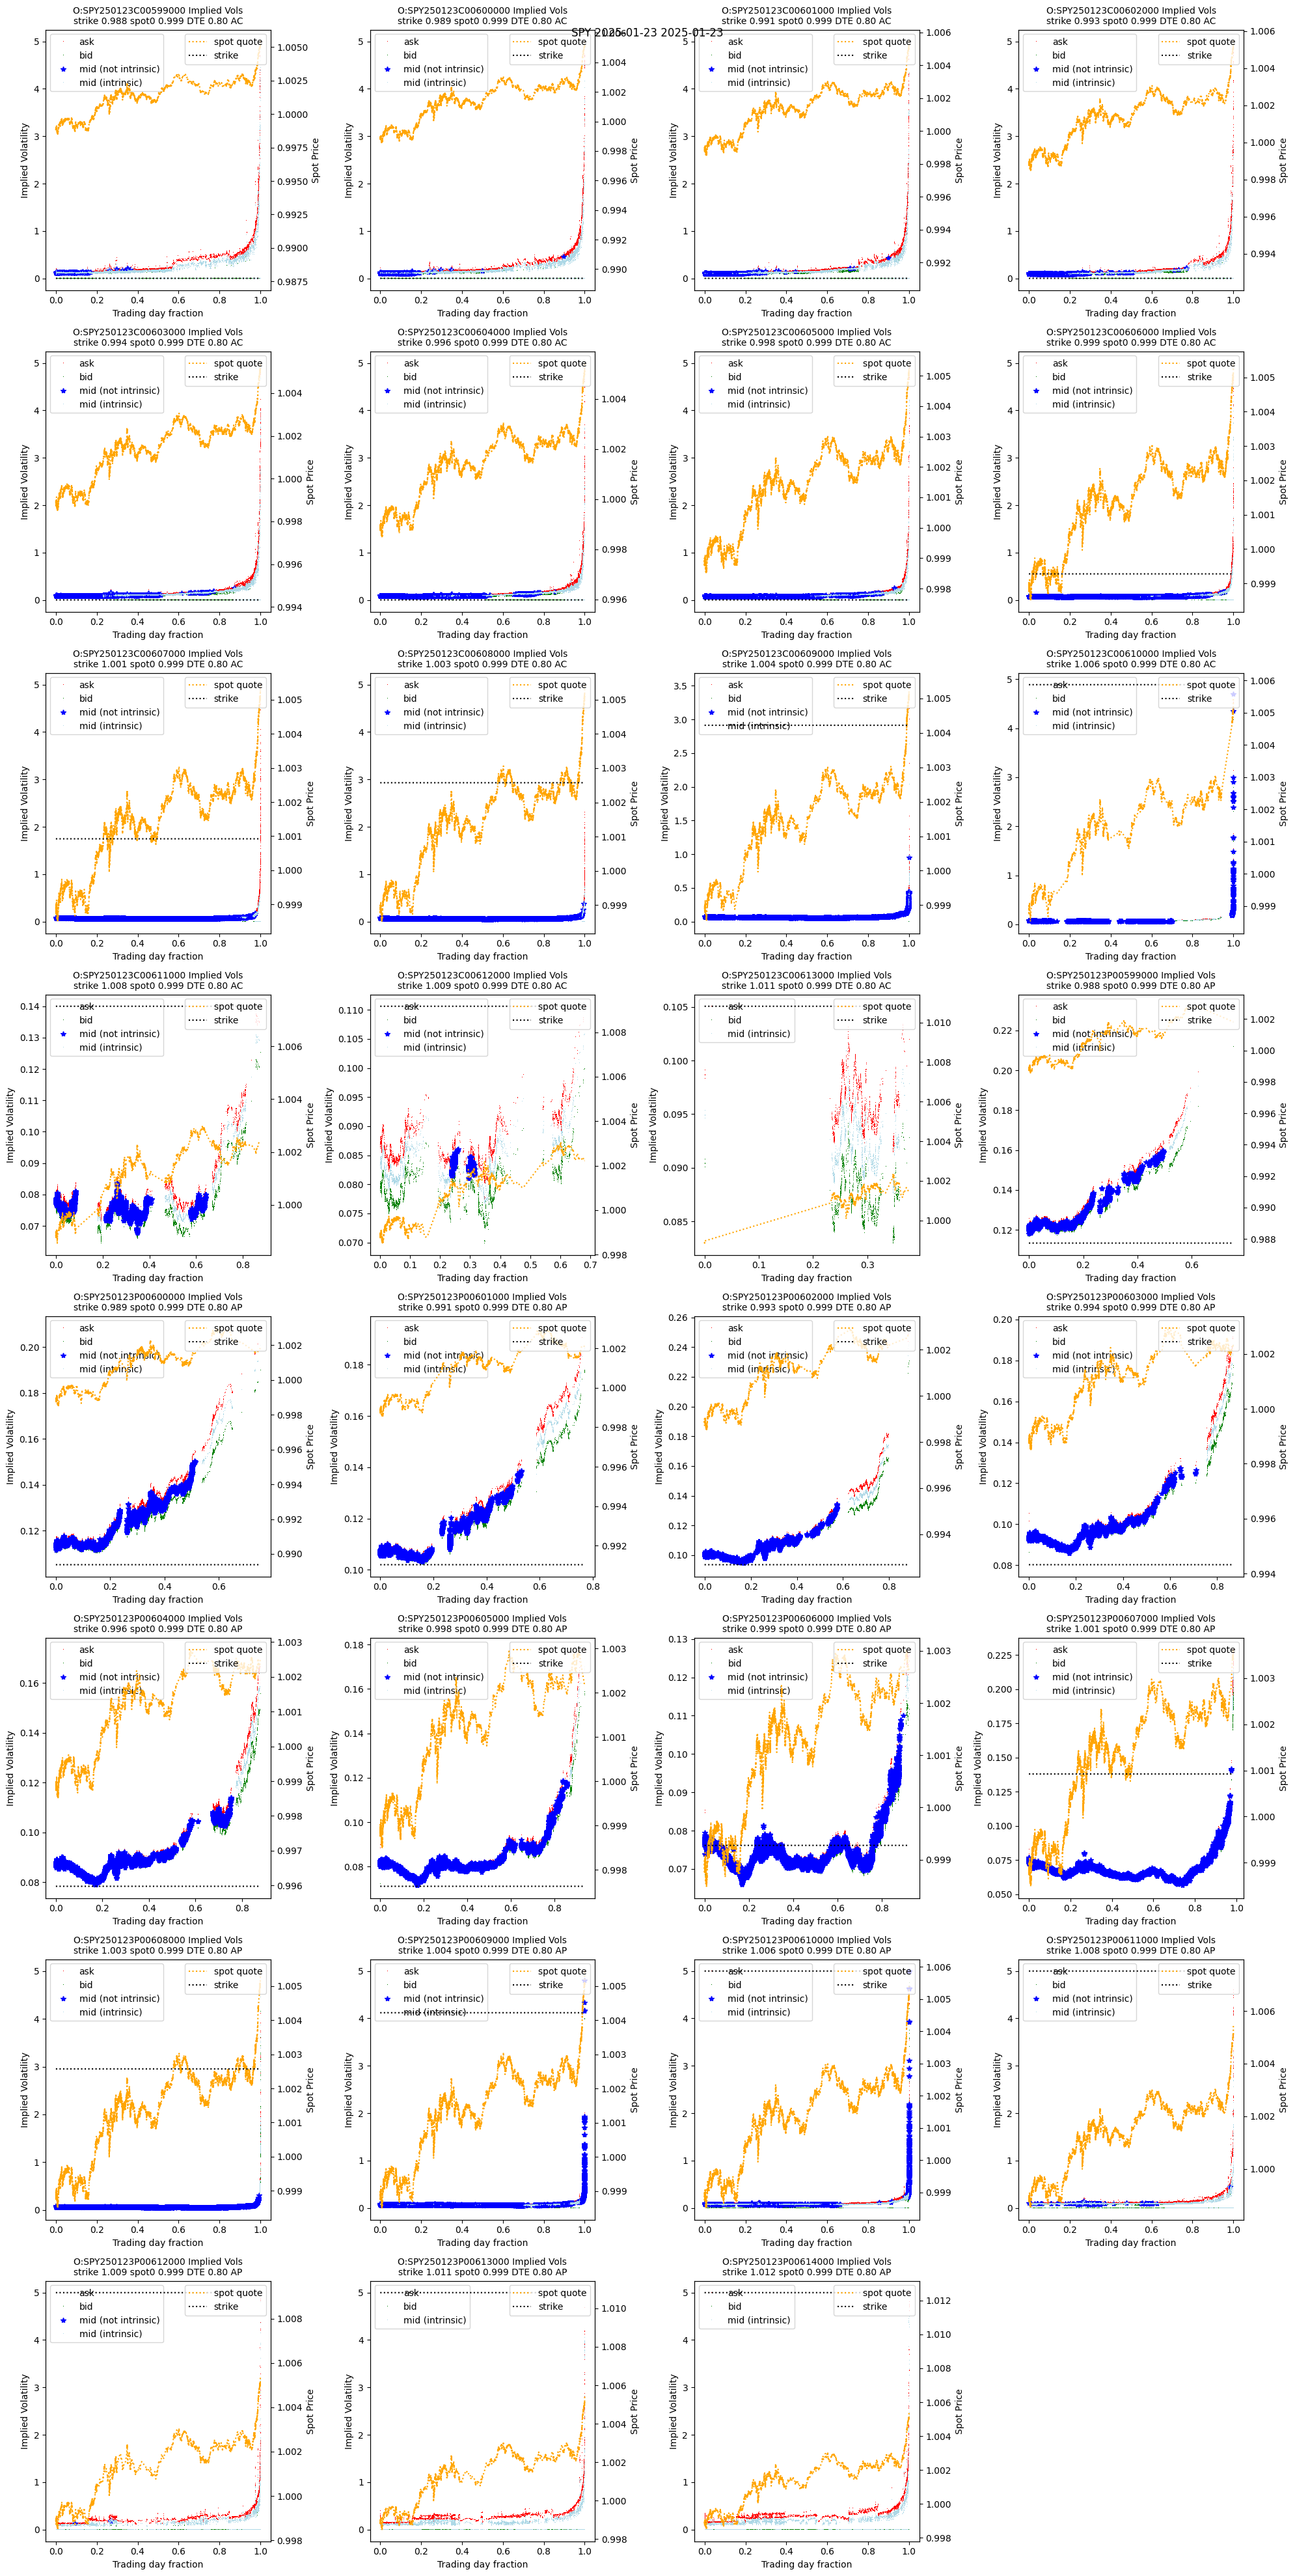

In [ ]:
from cdxcore.dynaplot import figure, colors_tableau

def plot_expiry( ticker, d, expiry ):
    display(Markdown(f"## Expiry {expiry} for {ticker} {d}"))

    opt_tickers = sorted( df_dict["opt_ticker"].unique().to_list() )
    date = df_dict["date"].unique()[0] if "date" in df_dict.columns else d

    with figure(f"SPY {expiry} {date}", row_size=5, col_size=5, columns=4) as fig:

        for opt_ticker in opt_tickers:
            df_opt = df_dict.filter(pl.col("opt_ticker") == opt_ticker)
            slc    = slice(None,None)

            opt_mid_vol      = df_opt["mid_vol"].to_numpy()[slc]
            opt_ask_vol      = df_opt["ask_vol"].to_numpy()[slc]
            opt_bid_vol      = df_opt["bid_vol"].to_numpy()[slc]
            spot_mid_price   = df_opt["spot_mid_price"].to_numpy()[slc]
            spot_quote_t_d   = df_opt["spot_quote_t_d"].to_numpy()[slc]
            t_d              = df_opt["t_d"].to_numpy()[slc]
            is_intrinsic     = df_opt["is_intrinsic"].to_numpy()[slc]

            strike           = df_opt["strike"].unique()[0]
            is_call          = df_opt["is_call"].unique()[0]
            is_american      = df_opt["is_american"].unique()[0]
            dte_0            = df_opt["dte"].to_numpy()[0]

            ax = fig.add_subplot()
            ax.set_title(f"{opt_ticker} Implied Vols\nstrike {strike:.3f} spot0 {spot_mid_price[0]:.3f} DTE {dte_0:.2f} {'A' if is_american else 'E'}{'C' if is_call else 'P'}", fontsize=10)
            ax2 = ax.twinx()
            ax.plot(t_d, opt_ask_vol, ",", color="red", label="ask")
            ax.plot(t_d, opt_bid_vol, ",", color="green", label="bid")
            if not np.all(is_intrinsic):
                ax.plot(t_d[~is_intrinsic], opt_mid_vol[~is_intrinsic], "*", color="blue", label="mid (not intrinsic)")
            if np.any(is_intrinsic):
                ax.plot(t_d[is_intrinsic], opt_mid_vol[is_intrinsic], ",", color="lightblue", label="mid (intrinsic)")

            ax2.plot(spot_quote_t_d, spot_mid_price, ":", color="orange", label="spot quote")
            ax2.plot(spot_quote_t_d, spot_quote_t_d*0.+strike, ":", color="black", label="strike")

            ax.set_xlabel("Trading day fraction")
            ax.set_ylabel("Implied Volatility")
            ax2.set_ylabel("Spot Price")
            ax.legend(loc="upper left")
            ax2.legend(loc="upper right")

for expiry, df_dict in results.items():
    plot_expiry( ticker, d, expiry )





In [9]:
zdte = results[date(2025, 1, 23)].filter(pl.col("opt_ticker") == "O:SPY250123P00603000")
zdte = zdte.with_columns( ( pl.col("mid_price") - pl.col("half_spread") ).alias("bid_price") )

pl.Config.set_tbl_rows(-1)
display(zdte['strike', 'dte', 'bid_price', "intrinsic", "is_intrinsic", "bid_vol", "opt_tick_size"].tail(100))

strike,dte,bid_price,intrinsic,is_intrinsic,bid_vol,opt_tick_size
f64,f64,f64,f64,bool,f64,f64
0.994328,0.117842,0.000016,0.0,true,0.162777,0.000016
0.994328,0.117742,0.000016,0.0,true,0.162846,0.000016
0.994328,0.117719,0.000016,0.0,true,0.162862,0.000016
0.994328,0.117699,0.000016,0.0,true,0.162726,0.000016
0.994328,0.11745,0.000016,0.0,true,0.162297,0.000016
0.994328,0.11745,0.000016,0.0,true,0.162297,0.000016
0.994328,0.117447,0.000016,0.0,true,0.162449,0.000016
0.994328,0.117427,0.000016,0.0,true,0.163515,0.000016
0.994328,0.11742,0.000016,0.0,true,0.16352,0.000016


In [5]:
from cdxcore.bs import bs

bs.price( 1.004221, )

TypeError: BS.price() missing 1 required positional argument: 'vol'